Imports

In [1]:
from ydata_profiling import ProfileReport
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
%matplotlib inline

c:\Users\PedroJorge\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_14828\638726203.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


# Importing data and making data profile

In [2]:
DATA_DIR = Path("..") / "data"
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")

In [3]:
REPORTS_DIR = Path("..") / "reports"
report_path_f = REPORTS_DIR / "freight_profile.html"
report_path_w = REPORTS_DIR / "weather_profile.html"
if not report_path_f.exists():
    profile_freight = ProfileReport(df_freight, title="Rhine Freight - Data Profile", explorative=True)
    profile_freight.to_file(report_path_f)
    profile_weather = ProfileReport(df_weather, title="Weather Data Basel - Data Profile", explorative=True)
    profile_weather.to_file(report_path_w)

exploring

In [4]:
df_freight.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar'],
      dtype='object')

# Missing values

In [5]:
df_freight.shape


(1469, 8)

In [6]:
df_freight.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1469 entries, 0 to 1468
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          1469 non-null   object 
 1   Freight       1454 non-null   float64
 2   Mogas_Flat    1469 non-null   float64
 3   Brent_flat    1469 non-null   float64
 4   Diesel_Flat   1469 non-null   float64
 5   Heating_Flat  1469 non-null   float64
 6   Kaub_level    1456 non-null   float64
 7   freight_ar    723 non-null    float64
dtypes: float64(7), object(1)
memory usage: 91.9+ KB


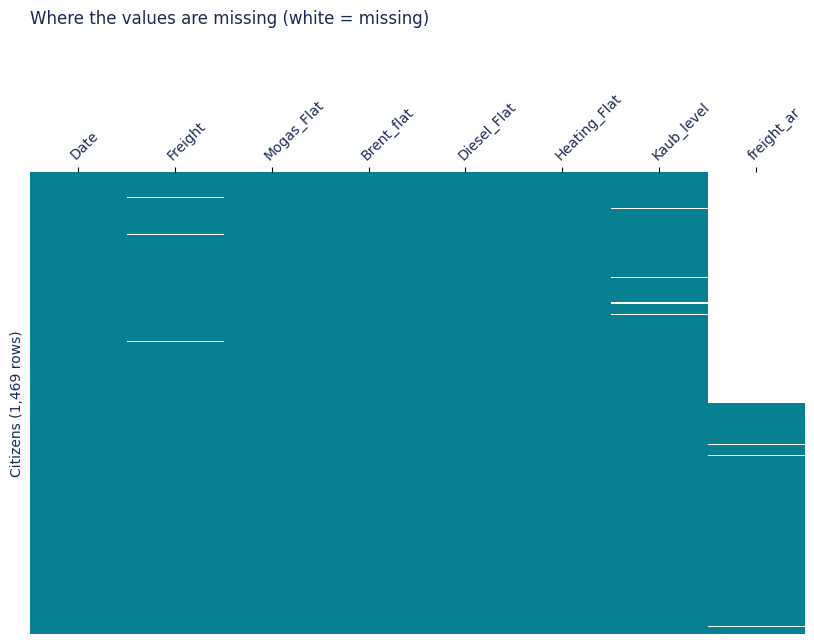

In [7]:
from matplotlib.colors import ListedColormap

NAVY, TEAL = "#1c2a56", "#078091"
FILL = TEAL                    # colour of the cells that have a value
TEXT = NAVY


SORT_ROWS = False              # True: group citizens with the same gaps together (blocks are easier to see)
present = df_freight.notna()
if SORT_ROWS:
    present = present.sort_values(list(present.columns), ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(present.values, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["white", FILL]), vmin=0, vmax=1)   # True = coloured, NaN = white

ax.set_xticks(range(present.shape[1]))
ax.xaxis.tick_top()
ax.set_xticklabels(present.columns, rotation=45, ha="left", rotation_mode="anchor", color=TEXT)
ax.set_ylabel(f"Citizens ({len(df_freight):,} rows)", color=TEXT)
ax.set_yticks([])
ax.set_title("Where the values are missing (white = missing)", loc="left", color=TEXT, pad=48)
for s in ax.spines.values():
    s.set_visible(False)

plt.savefig("missing_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

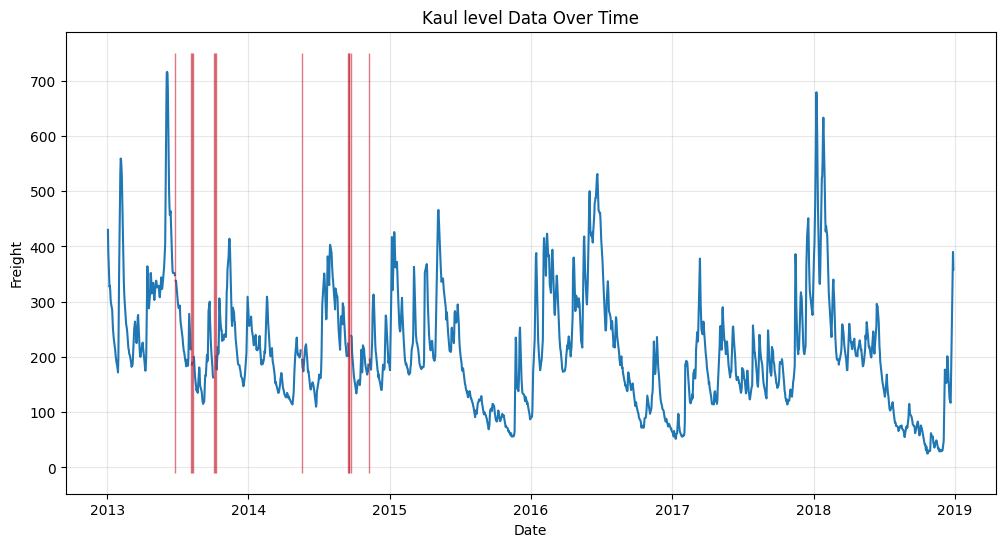

In [8]:
#looking at the gaps

df_freight["Date"] = pd.to_datetime(df_freight["Date"], format="%d/%m/%Y")
df_freight = df_freight.sort_values("Date")

missing_dates = df_freight.loc[df_freight["Kaub_level"].isna(), "Date"]


fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_freight["Date"], df_freight['Kaub_level'])
ax.set_title("Kaul level Data Over Time")
ax.vlines(missing_dates, *ax.get_ylim(), color="#c52030", alpha=0.6, lw=1,
          label=f"Missing ({len(missing_dates)} days)")
ax.set_xlabel("Date")
ax.set_ylabel("Freight")
ax.grid(True, alpha=0.3)
plt.show()
plt.close(fig)

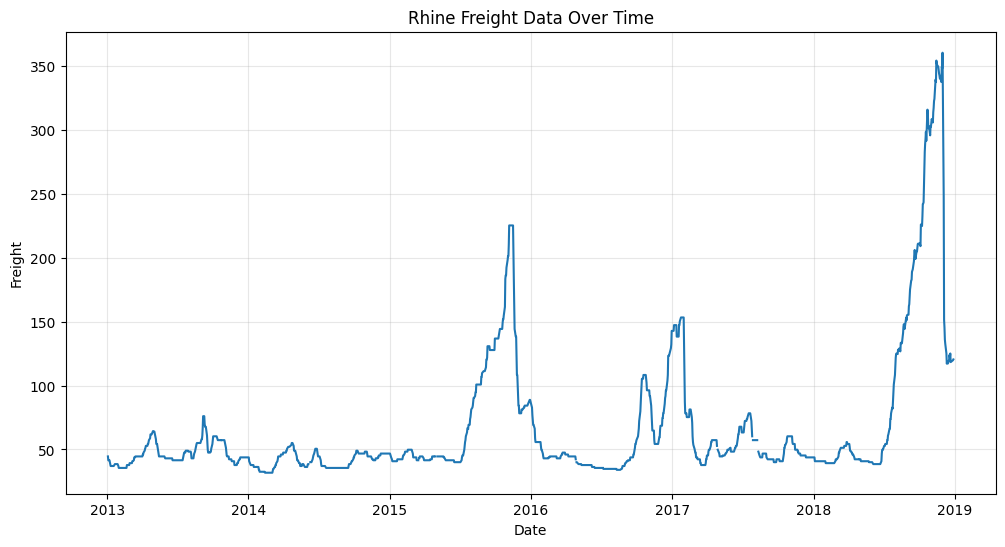

In [9]:
df_freight["Date"] = pd.to_datetime(df_freight["Date"], format="%d/%m/%Y")
df_freight = df_freight.sort_values("Date")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_freight["Date"], df_freight['Freight'])
ax.set_title("Rhine Freight Data Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Freight")
ax.grid(True, alpha=0.3)
plt.show()
plt.close(fig)

- no paired missing values
- unprobable that missings = 0 as seen in the figure
- Missings in the freight_ar before 2016, can be due to new implementation of the tariff at the ar region

Missing values in the target variables (Freight and freight_ar) mean that that training rows are not useful - delete them
Kaub_level missing values can maybe be estimated by surrounding values

In [10]:
df_weather.isna().sum()

date                    0
avg_uv_index            0
avgtemp                 0
cloudcover              0
dewpoint                0
feelslike               0
heatindex               0
humidity                0
maxtemp                 0
mintemp                 0
moon_illumination       0
moon_phase              0
precip                  0
pressure                0
sunhour                 0
totalsnow               0
uv_index                0
visibility              0
weather_code            0
weather_descriptions    0
wind_degree             0
wind_dir                0
wind_speed              0
windchill               0
windgust                0
dtype: int64

no missing values in the weather dataset